In [6]:
# Import standard packages
import pandas as pd
import numpy as np
import datetime
import time
import os

# Import packages for display formatting/graph plotting
import ipywidgets as widgets
import matplotlib.pyplot as plt
from IPython.display import Image

# Import packages Quantifi Toolkit packages 
from Quantifi.Toolkit.Products import Bond
from Quantifi.Toolkit.Pricers import BondPricer
from Quantifi.Toolkit.Base import Dt, DayCount, Frequency, Calendar, QuotingConvention, BumpTarget
from Quantifi.Toolkit.Sensitivity import Sensitivities, Sensitivities2, BumpType, SensitivityMethod
from Quantifi.Toolkit.Curves import CurveUtil

# Import Quantifi Rest API client functions
from qservices.QuantifiApiClient import *

### Set Access Parameters

Next, we define some access parameters for loading data from Quantifi Risk Database:

In [7]:
# Define database access parameters and pricing date

# For locally installed Quantifi Risk
#os.environ["Q_DATA_SERVICE_URL_PREFIX"] = "https://hb-dc1ut-qfidsp:47200"   #UAT URL
os.environ["Q_DATA_SERVICE_URL_PREFIX"] = "https://hb-dc1pd-qfidsp:47200" #Prod URL
#os.environ["Q_MARKET_ENV_SERVICE_URL_PREFIX"] = "https://hb-dc1ut-qfidsp:47201"  #UAT URL
os.environ["Q_MARKET_ENV_SERVICE_URL_PREFIX"] = "https://hb-dc1pd-qfidsp:47201" #Prod URL
os.environ["Q_LOCAL_INSTALL"] = "True"

# Suppress warnings due to unverified HTTPS certificate
requests.packages.urllib3.disable_warnings()

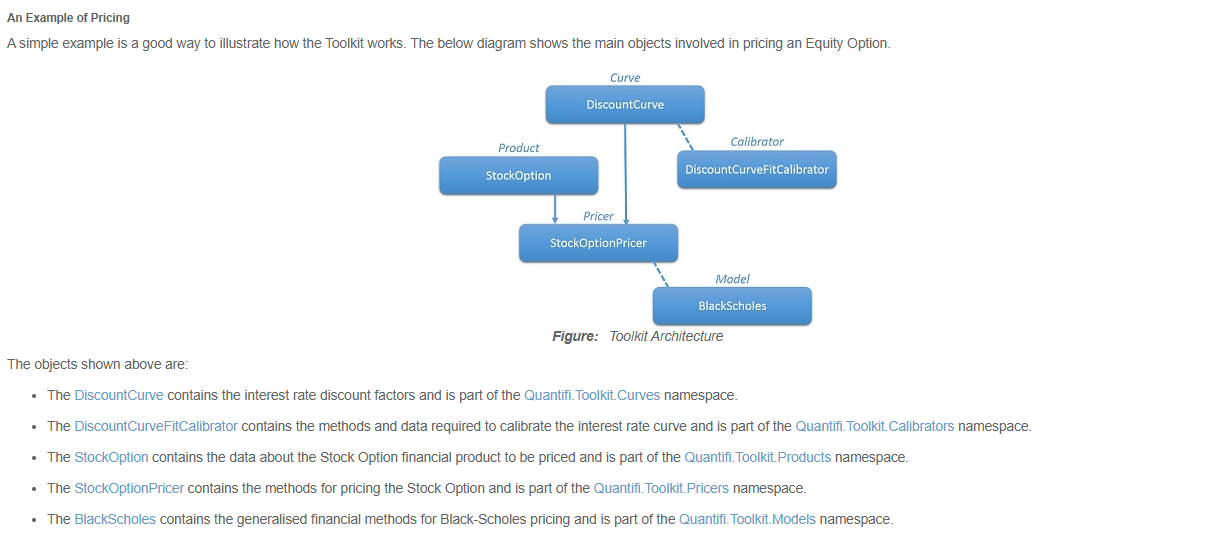

In [8]:
Image("toolkit_visual.png")

### Extract Objects from the Database and Risk App

We can now load a set of interest rate (discount) curves from Quantifi Risk system for the specific pricing date and calculation environment sepcified above. Note that these curves will be calibrated by Quantifi Risk engine on the fly and passed as already calibrated objects directly to the Python code below. We will store them in a Python dictionary indexed by the curve name.

In [ ]:
### Retrieve rate curve configurations from the database 
rate_hql = "FROM RateCurveConfig r WHERE r.CalcEnv = 'Official'" # AND r.Currency =" + str(int(Currency.USD)) # ANY DATA YOU SEE IN DATA EXPLORFER U CAN DOWNLOAD HERE
rate_info = Connect.data_query(hql = rate_hql, verify_https_cert = False) # hibernate query language. # data_query funnction is fromt he API client module
# This function takes an optional param called ds_url which will default to the url we set above:
# os.environ["Q_DATA_SERVICE_URL_PREFIX"] = "https://hb-dc1pd-qfidsp:47200"

for rate in rate_info:
    print(rate)

{'$type': 'RateCurveConfig', 'ObjectId': '57420895248977408', 'ValidFrom': '', 'Name': 'SEKSTIBOR', 'CalcEnv': 'Official', 'RateCurveType': 'Standard', 'RateFutureTenor': '3 Months', 'Currency': 'SEK', 'InterpMethod': 'Weighted', 'ExtrapMethod': 'Const', 'CreateAsOverlay': False, 'MMBDConvention': 'Modified', 'EDBDConvention': 'Modified', 'SwapBDConvention': 'Modified', 'MMCalendar': 'STB', 'EDCalendar': 'STB', 'SwapCalendar': 'STB', 'BasisSwapCalendar': 'TGT', 'BasisSwapDayCount': 'None', 'BasisSwapBDConvention': 'None', 'BasisSwapFrequency': 'None', 'BasisSwapReceiveFrequency': 'None', 'MMDayCount': 'Actual360', 'MMTenors': [{'$type': 'RateCurveTenor', 'Name': '1 Weeks', 'Reference': 'SEKSTIBOR.1 Weeks.Mid', 'HedgeInstrument': True}, {'$type': 'RateCurveTenor', 'Name': '1 Months', 'Reference': 'SEKSTIBOR.1 Months.Mid', 'HedgeInstrument': True}, {'$type': 'RateCurveTenor', 'Name': '2 Months', 'Reference': 'SEKSTIBOR.2 Months.Mid', 'HedgeInstrument': True}, {'$type': 'RateCurveTenor', 

: 

In [ ]:
# HQL testing

